# 쇼핑몰 고객 문의 텍스트 분류
### 문의 한 문장을 읽고 **배송 / 환불 / 상품** 중 어떤 문의인지 맞히는 모델 만들기

**환경:** Google Colab (인터넷 연결 필요)
**준비물 (파일 1개)**
| 파일 | 내용 |
|---|---|
| `shop_inquiry.csv` | 쇼핑몰 문의 600줄 (번호, **문의**, **유형**, 출처) — 실제 쇼핑 상담 대화에서 뽑은 고객 데이터 600줄 |

**소요 시간:** 약 40분

## 오늘의 상황
> 쇼핑몰 고객센터에 하루에도 수백 개의 문의가 들어옵니다. 담당자가 하나하나 읽고 **배송팀 / 환불팀 / 상품팀**으로 나누려면 시간이 오래 걸립니다.
> 문의 문장을 읽고 **유형을 자동으로 붙여 주는 모델**을 만들어 봅시다.

```
"택배가 아직도 안 와요ㅠㅠ"  ──▶  [ 분류 모델 ]  ──▶  배송
```

## 실습 진행 과정
| 단계 | 할 일 | 산출물 |
|---|---|---|
| 0. 준비 | 설치, 파일 읽기 | 원본 표 |
| 1. 텍스트 전처리 | 빈 칸·중복 지우기 → 특수문자 지우기 → 형태소 분석 → 불용어 빼기 | 처리 전/후 비교 |
| 2. 정제 데이터셋 | 저장, 유형별 개수 확인 | `inquiry_clean.csv` |
| 3. 텍스트 분석 | 유형별 자주 나오는 단어 → 학습/평가 나누기 → TF-IDF → 모델 학습 | 학습된 모델 |
| 4. 분석 결과 | 정확도·F1, 혼동행렬, 중요 단어, 틀린 문장·출처별 정확도, 내 문장 예측 | 그래프 6개 |
| 정리 | 한계, 연습문제 |

> **실행 방법:** 셀을 클릭하고 `Shift + Enter`. 반드시 **위에서부터 순서대로** 실행하세요.
> ✏️ 표시가 있는 곳은 **직접 바꿔 볼 수 있는 부분**입니다.

> ⚠️ **실습용으로 만든 데이터입니다.** 절반은 사람이 직접 쓴 문장이고, 나머지 절반은 실제 상담 대화에서 고객이 한 말을 골라 왔습니다. 정답(유형)은 두 경우 모두 사람이 붙였습니다. `출처` 열로 둘을 구분할 수 있습니다.

---
## 0. 준비
| 도구 | 하는 일 |
|---|---|
| `pandas` | 표 다루기 (Colab에 기본 설치) |
| `kiwipiepy` | 한국어 형태소 분석기 Kiwi |
| `koreanize-matplotlib` | 그래프에 한글 글꼴 설정 |
| `scikit-learn` | TF-IDF, 분류 모델, 평가 (Colab에 기본 설치) |

In [1]:
# 도구 설치 (처음 한 번만 실행)
# !     : 파이썬 코드가 아니라 리눅스 명령어를 실행하라는 표시
# pip install : 파이썬 도구(패키지)를 인터넷에서 내려받아 설치하는 명령어
# -q    : 설치 과정 메시지를 짧게 줄여서 보여 줌
# kiwipiepy            : 한국어 형태소 분석기 Kiwi
# koreanize-matplotlib : 그래프 한글 글꼴(나눔고딕) 자동 설정 도구
!pip install -q kiwipiepy koreanize-matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.9/87.9 MB 9.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 36.4 MB/s eta 0:00:00


Colab 왼쪽 **📁 파일 창**에 `shop_inquiry.csv` 파일을 끌어다 놓은 뒤 다음 셀을 실행하세요.

In [2]:
import pandas as pd                     # 표(DataFrame)를 다루는 도구, pd라는 짧은 이름으로 부름

# CSV 파일 읽기
#   pd.read_csv : CSV 파일을 읽어서 표(DataFrame)로 만듦
#   encoding="utf-8-sig" : 이 파일의 한글 저장 방식 (엑셀에서도 한글이 안 깨지는 방식)
df = pd.read_csv("shop_inquiry.csv", encoding="utf-8-sig")

# len(df) : 표의 줄(행) 개수
print("문의 수:", len(df))
# 위에서 5줄 보여 주기
df.head()

문의 수: 600


,번호,문의,유형,출처
0,1,아. 손님용으로 샀는데 안 받는다고 해서 취소하려고요.,환불,실제 상담
1,2,주소를 잘못 입력했어요 수정 가능한가요?,배송,직접 작성
2,3,3월 5일 주문 건 아직 못 받았어요,배송,직접 작성
3,4,아 여보세요. 지금 주문을 했는데 취소할려고요.,환불,실제 상담
4,5,방송에서 세탁기 돌려도 된다고 해서 산건데 세탁기 돌리고 나니 사용할 수가 없잖아요.,상품,실제 상담


✅ **결과 확인:** 문의 600줄, 열은 `번호`, `문의`(고객 문장), `유형`(정답: 배송·환불·상품), `출처`(직접 작성 / 실제 상담) 4개입니다. 실제 상담 문장은 말로 한 것을 받아 적은 것이라 `네,`, `아 그럼`처럼 말버릇이 섞여 있고, 숫자도 `구십오`처럼 한글로 적혀 있습니다.

---
## 1. 텍스트 데이터 전처리
컴퓨터가 문장을 잘 배우도록 **필요 없는 것은 지우고, 중요한 단어만 남기는** 단계입니다.

| 순서 | 할 일 | 이유 |
|---|---|---|
| 1-1 | 빈 칸 지우기 | 문장이 없으면 배울 것이 없음 |
| 1-2 | 중복 문장 지우기 | 같은 문장이 학습과 평가에 둘 다 들어가면 점수가 부풀려짐 |
| 1-3 | 특수문자·이모티콘 지우기 | `!!!`, `ㅠㅠ`, `😢`는 유형을 나누는 데 도움이 적음 |
| 1-4 | 형태소 분석 | 문장을 뜻 있는 단어 조각으로 나눔 |
| 1-5 | 불용어 빼기 | `하다`, `있다`처럼 어느 유형에나 나오는 말 빼기 |

### 1-1. 빈 칸 지우기

In [3]:
# 열마다 빈 칸(NaN) 개수 세기
#   df.isna() : 칸마다 비어 있으면 True, 아니면 False
#   .sum()    : 열마다 True 개수를 더함
print("빈 칸 개수:")
print(df.isna().sum())

# 빈 칸이 하나라도 있는 줄 지우기
df = df.dropna()
print("\n빈 칸을 지운 뒤 문의 수:", len(df))

빈 칸 개수:
번호    0
문의    5
유형    0
출처    0
dtype: int64

빈 칸을 지운 뒤 문의 수: 595


### 1-2. 중복 문장 지우기

In [5]:
# '문의' 열에서 앞에 이미 나온 문장과 똑같은 줄 개수
#   df.duplicated("문의") : 앞에 같은 문장이 있으면 True
print("중복 문장 수:", df.duplicated("문의").sum())

# 같은 문장은 첫 번째 줄만 남기고 지우기
#   reset_index(drop=True) : 줄 번호를 0, 1, 2, … 로 다시 매김
df = df.drop_duplicates("문의").reset_index(drop=True)
print("중복을 지운 뒤 문의 수:", len(df))

중복 문장 수: 0
중복을 지운 뒤 문의 수: 585


✅ **결과 확인:** 600줄 → 빈 칸 5줄 → 중복 10줄을 지워서 **585줄**이 남습니다.

### 1-3. 특수문자·이모티콘 지우기 (정규식)
**정규식**은 '글자 패턴'으로 찾고 바꾸는 방법입니다. `[^가-힣0-9 ]`는 **한글, 숫자, 공백이 아닌 글자 1개**라는 뜻입니다.

In [6]:
import re                               # 정규식(글자 패턴 찾기·바꾸기) 도구

# 문장 하나 → 정리된 문장
def clean(text):
    # [^가-힣0-9 ] : 한글(가~힣)·숫자·공백이 아닌 글자 → 공백으로 바꿈 (!, ?, ㅠ, 😢 등)
    text = re.sub(r"[^가-힣0-9 ]", " ", text)
    # \s+ : 공백 1개 이상 → 공백 1개로,  .strip() : 앞뒤 공백 지우기
    return re.sub(r"\s+", " ", text).strip()

# 모든 문의에 clean을 적용해서 '정제' 열로 저장
df["정제"] = df["문의"].apply(clean)

# 처리 전/후 비교: 특수문자가 있던 문장만 골라 5개 보기
#   str.contains(r"[!ㅠ😢😡😍]") : 문의에 이 글자 중 하나라도 있으면 True
df[df["문의"].str.contains(r"[!ㅠ😢😡😍]")][["문의", "정제"]].head()

,문의,정제
12,택배가 아직도 안 와요ㅠㅠ,택배가 아직도 안 와요
43,환불 처리 빨리 부탁드려요 😡,환불 처리 빨리 부탁드려요
105,물이 새요!!,물이 새요
190,반품 신청했는데 연락이 없어요!!,반품 신청했는데 연락이 없어요
241,배송 예정일이 지났어요!!!,배송 예정일이 지났어요


### 1-4. 형태소 분석 (Kiwi)
**형태소**는 뜻을 가진 가장 작은 말 덩어리입니다. Kiwi는 문장을 형태소로 나누고 **품사**를 붙여 줍니다. 한 문장으로 먼저 확인해 봅시다.

| 품사 기호 | 뜻 | 예 |
|---|---|---|
| `NNG` | 일반명사 | 배송, 환불, 사이즈 |
| `NNP` | 고유명사 | 제주도 |
| `VV` | 동사 | 오(다), 받(다) |
| `VA` | 형용사 | 작(다), 늦(다) |

In [7]:
from kiwipiepy import Kiwi              # 한국어 형태소 분석기
kiwi = Kiwi()                           # 분석기 준비 (처음 한 번 몇 초 걸림)

# 예시 문장 하나를 형태소로 나누기
#   kiwi.tokenize(문장) : 형태소 목록,  t.form : 글자,  t.tag : 품사
# ✏️ 다른 문장으로 바꿔 보세요
tokens = kiwi.tokenize("사이즈가 생각보다 작아서 환불하고 싶어요")
pd.DataFrame([(t.form, t.tag) for t in tokens], columns=["형태소", "품사"]).T   # .T : 가로로 눕혀서 보기

,0,1,2,3,4,5,6,7,8,9,10
형태소,사이즈,가,생각,보다,작,어서,환불,하,고,싶,어요
품사,NNG,JKS,NNG,JKB,VA,EC,NNG,XSV,EC,VX,EF


✅ **결과 확인:** `사이즈`·`생각`·`환불`은 명사(`NNG`), `작`은 형용사(`VA`)로 나뉩니다. `가`, `어서`, `고` 같은 조사·어미는 뜻을 나누는 데 필요 없으므로 다음 단계에서 뺍니다.

### 1-5. 명사·동사·형용사만 남기고 불용어 빼기
- 동사·형용사는 `작` → `작다`처럼 **'다'를 붙여** 읽기 쉽게 만듭니다.
- **✏️ 불용어 `STOP`**: 어느 유형에나 나오는 말은 뺍니다.

In [8]:
# ✏️ 불용어: 유형을 나누는 데 도움이 안 되는 말
STOP = {"하다", "되다", "있다", "없다", "이다", "주다", "보다", "좀", "것", "수",
        "어디", "언제", "어떻게", "어떻다", "뭐", "왜"}

# 문장 하나 → 단어를 공백으로 이은 글자 (예: '사이즈 생각 작다 환불')
def to_words(text):
    words = []                                          # 남길 단어를 모을 빈 목록
    for t in kiwi.tokenize(text):                       # 형태소를 하나씩 꺼냄
        if t.tag in ("NNG", "NNP"):                     # 명사면
            words.append(t.form)                        #   글자 그대로 추가
        elif t.tag.startswith(("VV", "VA")):            # 동사·형용사면 (VV-R 같은 변형 품사 포함)
            words.append(t.form + "다")                 #   '다'를 붙여 추가
    # 불용어가 아닌 단어만 공백으로 이어 붙여 돌려줌
    return " ".join(w for w in words if w not in STOP)

# 모든 정제 문장에 to_words를 적용해서 '단어' 열로 저장 (몇 초 걸림)
df["단어"] = df["정제"].apply(to_words)

# 처리 전/후 비교 5개 (random_state=1 : 실행할 때마다 같은 5줄)
df[["문의", "단어", "유형"]].sample(5, random_state=1)

,문의,단어,유형
0,아. 손님용으로 샀는데 안 받는다고 해서 취소하려고요.,손님 사다 받다 취소,환불
546,그러면 지금 전산에는 배송 완료된 걸로 되어 있겠네요?,전산 배송 완료,배송
355,배송은 빨랐는데 전원이 안 켜져요,배송 빠르다 전원 켜다,상품
23,배송비도 당연히 무료 맞죠?,배송비 무료 맞다,배송
385,그런데 제가 상품을 안 왔거든요?,상품 오다,배송


✅ **결과 확인:** `택배가 아직도 안 와요ㅠㅠ` → `택배 오다`처럼 **유형을 알려 주는 핵심 단어**만 남았나요?

---
## 2. 정제 데이터셋
전처리 결과를 파일로 저장하고, 유형별 문의 수와 문장 길이를 확인합니다.

In [9]:
# 정제 데이터셋 저장 (index=False : 줄 번호는 저장하지 않음)
df[["문의", "정제", "단어", "유형"]].to_csv("inquiry_clean.csv", index=False, encoding="utf-8-sig")
print("저장 완료: inquiry_clean.csv /", len(df), "줄")

저장 완료: inquiry_clean.csv / 585 줄


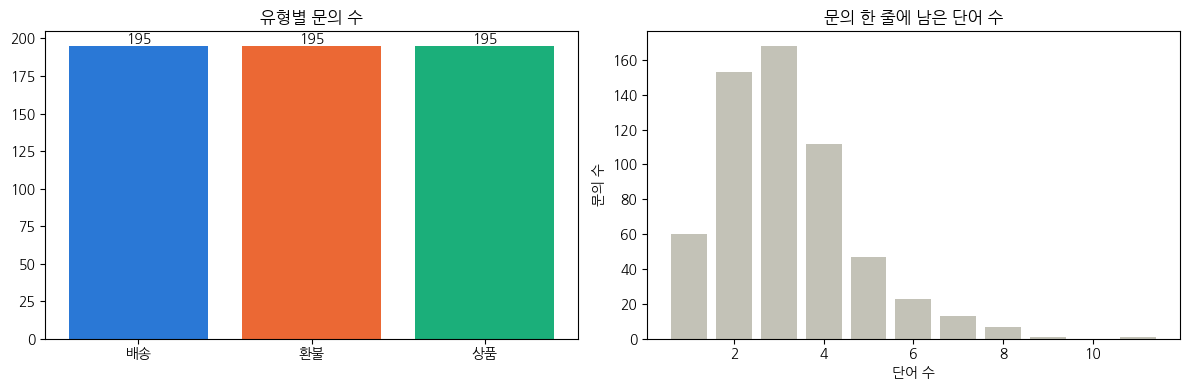

In [10]:
import matplotlib.pyplot as plt         # 그래프 그리는 도구
import koreanize_matplotlib             # 불러오기만 하면 그래프 한글 글꼴이 설정됨

LABELS = ["배송", "환불", "상품"]                        # 유형 순서
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]              # 유형별 색 (파랑, 주황, 초록)

# 그림 2칸 (왼쪽, 오른쪽),  figsize : 그림 크기 (가로 12, 세로 4 인치)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# (왼쪽) 유형별 문의 수 막대그래프
#   value_counts() : 유형별 개수,  reindex(LABELS) : LABELS 순서로
counts = df["유형"].value_counts().reindex(LABELS)
axes[0].bar(counts.index, counts.values, color=COLORS)
axes[0].bar_label(axes[0].containers[0])               # 막대 위에 숫자 쓰기
axes[0].set_title("유형별 문의 수")

# (오른쪽) 문의 한 줄의 단어 수별 문의 수
#   str.split() : 단어 목록,  str.len() : 목록 길이 = 단어 수
#   value_counts().sort_index() : 단어 수별 문의 수를 단어 수 순서(1, 2, 3, …)로
n_words = df["단어"].str.split().str.len().value_counts().sort_index()
axes[1].bar(n_words.index, n_words.values, color="#c3c2b7")
axes[1].set_title("문의 한 줄에 남은 단어 수")
axes[1].set_xlabel("단어 수")
axes[1].set_ylabel("문의 수")

plt.tight_layout()                                       # 그래프끼리 겹치지 않게 간격 조정
plt.show()

✅ **결과 확인:**
- 세 유형의 문의 수가 **비슷합니다**(한쪽으로 쏠리지 않음). 한 유형이 아주 많으면 모델이 그 유형만 찍어도 점수가 높게 나오므로 먼저 확인해야 합니다.
- 문의 한 줄에 남은 단어는 대부분 **2~4개**입니다. 짧은 문장이라 단어 하나하나가 중요합니다.

---
## 3. 텍스트 분석

### 3-1. 유형별로 자주 나오는 단어 TOP 10
모델을 만들기 전에, **사람 눈으로 먼저** 유형마다 어떤 단어가 많은지 봅니다.

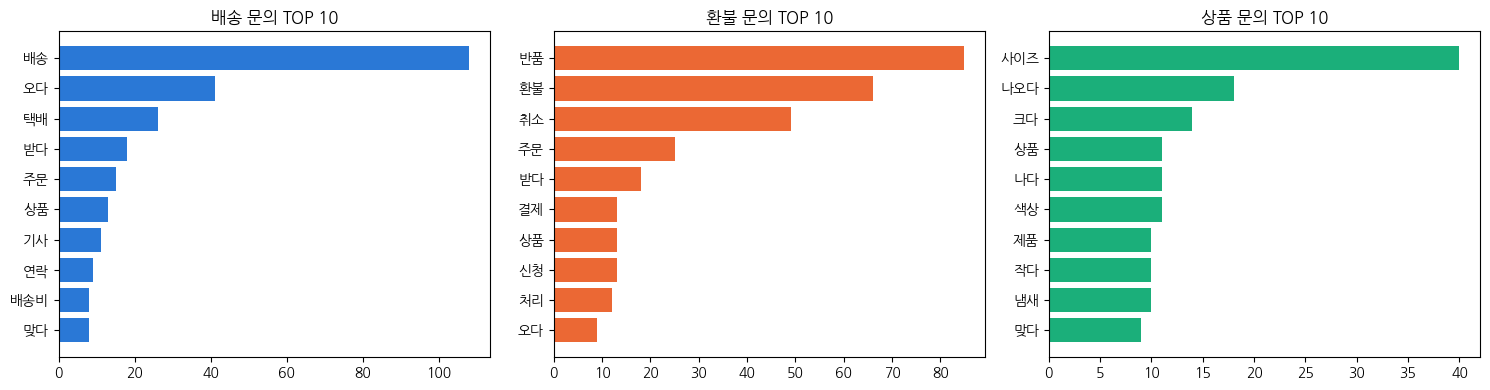

In [11]:
from collections import Counter         # 개수 세기 도구

# 그림 3칸 (유형마다 한 칸)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, label, color in zip(axes, LABELS, COLORS):     # 유형, 그래프 칸, 색을 하나씩 짝지어 꺼냄
    # 이 유형 문의의 단어를 모두 펼쳐서 세기
    #   " ".join(...) : 이 유형 문의의 단어 글자를 모두 이어 붙임,  .split() : 단어 목록
    words = " ".join(df[df["유형"] == label]["단어"]).split()
    top = pd.Series(dict(Counter(words).most_common(10)))   # 많이 나온 단어 10개
    ax.barh(top.index[::-1], top.values[::-1], color=color)   # [::-1] : 많은 단어가 위로
    ax.set_title(f"{label} 문의 TOP 10")

plt.tight_layout()
plt.show()

✅ **결과 확인:** `배송`·`오다`·`택배`는 배송, `반품`·`환불`·`취소`는 환불, `사이즈`·`크다`·`색상`은 상품에 많이 나오나요? 모델도 이런 단어를 단서로 배웁니다.
- 상품 문의에는 `사이즈`가 특히 많습니다. 실제 상담 문장에 옷·신발 사이즈 문의가 많기 때문입니다.
- `받다`, `상품`, `주문`처럼 **여러 유형에 같이 나오는 단어**도 있습니다. 이런 단어는 유형을 나누는 힘이 약합니다.

### 3-2. 학습용 / 평가용 나누기
시험 문제를 미리 보여 주면 실력을 알 수 없듯이, 모델도 **처음 보는 문장**으로 평가해야 합니다.
- **학습용 80%**: 모델이 정답을 보며 배우는 문장
- **평가용 20%**: 모델이 처음 보는 문장 → 점수 계산용

In [12]:
from sklearn.model_selection import train_test_split   # 학습용/평가용 나누는 도구

# test_size=0.2      : 20%를 평가용으로
# stratify=df["유형"] : 학습용·평가용 모두 유형 비율을 똑같이 맞춤
# random_state=0     : 실행할 때마다 똑같이 나눔
X_train, X_test, y_train, y_test = train_test_split(
    df["단어"], df["유형"], test_size=0.2, stratify=df["유형"], random_state=0)

print("학습용:", len(X_train), "줄 / 평가용:", len(X_test), "줄")

학습용: 468 줄 / 평가용: 117 줄


### 3-3. TF-IDF: 문장을 숫자로 바꾸기
모델은 글자를 읽지 못하므로 문장을 **숫자 표**로 바꿔야 합니다. **TF-IDF**는 단어마다 점수를 줍니다.
- 그 문장에 **나온 단어**일수록 점수가 높고 (TF)
- **여러 문장에 흔하게 나오는 단어**일수록 점수가 낮습니다 (IDF)

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer   # TF-IDF 숫자 표를 만드는 도구

# token_pattern=r"\S+" : 공백으로 나뉜 덩어리를 한 단어로 봄 (이미 단어를 나눠 두었으므로)
tfidf = TfidfVectorizer(token_pattern=r"\S+")

# fit_transform : 학습용 문장으로 단어장을 만들고(fit) 숫자 표로 바꿈(transform)
X_train_vec = tfidf.fit_transform(X_train)
# transform     : 평가용 문장은 학습용 단어장 그대로 숫자 표로만 바꿈 (평가용 단어는 배우지 않음)
X_test_vec = tfidf.transform(X_test)

print("단어장 크기:", len(tfidf.get_feature_names_out()), "개")
print("학습용 숫자 표 크기:", X_train_vec.shape, "(문장 수, 단어 수)")

# 학습용 문장 3개만 숫자 표로 보기
#   toarray() : 숫자 표를 보통 배열로,  columns : 열 이름 = 단어
sample = pd.DataFrame(X_train_vec[:3].toarray(), columns=tfidf.get_feature_names_out(), index=X_train[:3])
# (sample > 0).any() : 세 문장 중 하나라도 0보다 큰 열(단어)만 골라 보기, round(2) : 소수 둘째 자리까지
sample.loc[:, (sample > 0).any()].round(2)

단어장 크기: 484 개
학습용 숫자 표 크기: (468, 484) (문장 수, 단어 수)


,개봉,기간,도착,먹다,주문,지나다,환불,후
단어,,,,,,,,
주문 도착,0.00,0.00,0.82,0.00,0.57,0.00,0.00,0.00
환불 기간 지나다,0.00,0.59,0.00,0.00,0.00,0.73,0.36,0.00
개봉 후 먹다,0.63,0.00,0.00,0.56,0.00,0.00,0.00,0.54


✅ **결과 확인:** 단어장은 수백 개인데, 문장 하나에는 단어가 몇 개뿐이라 **대부분 0**입니다. 위 표는 0이 아닌 열만 골라 보여 준 것입니다.

### 3-4. 분류 모델 학습 (로지스틱 회귀)
**로지스틱 회귀**는 단어 점수를 보고 **유형마다 확률**을 계산해서, 확률이 가장 큰 유형을 고르는 모델입니다.

In [14]:
from sklearn.linear_model import LogisticRegression    # 로지스틱 회귀 분류 모델

# 모델 만들기 (max_iter=1000 : 배우는 계산을 최대 1000번까지 반복)
model = LogisticRegression(max_iter=1000)

# 학습: 숫자 표(X_train_vec)와 정답(y_train)을 보고 배움
model.fit(X_train_vec, y_train)

# 예측: 평가용 문장의 유형 맞히기
pred = model.predict(X_test_vec)

# 평가용 문장 5개의 정답과 예측 비교
pd.DataFrame({"문장 단어": X_test, "정답": y_test, "예측": pred}).head()

,문장 단어,정답,예측
401,알다 맛 괜찮다 방송 나오다 주문 맛 다르다,상품,상품
494,상품 냄새 나다 먹다,상품,상품
241,배송 예정일 지나다,배송,배송
247,배송비 환불,환불,환불
454,환불 가격 팩 빼다,환불,환불


---
## 4. 분석 결과

### 4-1. 정확도와 F1 점수
| 점수 | 뜻 |
|---|---|
| **정확도** | 전체 평가 문장 중 맞힌 비율 |
| **정밀도** | 모델이 '배송'이라고 한 것 중 진짜 배송인 비율 |
| **재현율** | 진짜 배송 문의 중 모델이 '배송'으로 찾아낸 비율 |
| **F1** | 정밀도와 재현율을 함께 본 점수 (둘 중 하나라도 낮으면 F1도 낮아짐) |

정확도  : 0.983
macro F1: 0.983


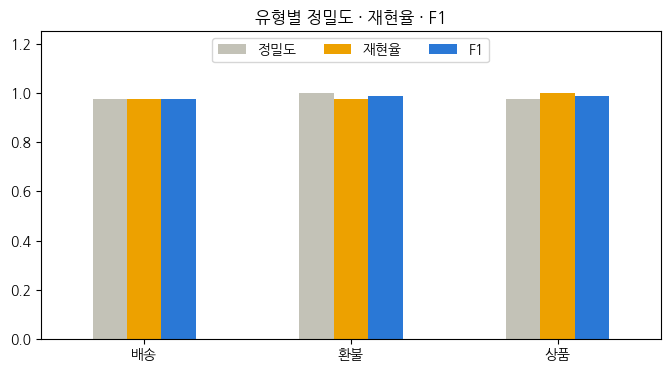

,정밀도,재현율,F1,문장 수
배송,0.974,0.974,0.974,39.0
환불,1.000,0.974,0.987,39.0
상품,0.975,1.000,0.987,39.0


In [15]:
from sklearn.metrics import accuracy_score, f1_score, classification_report   # 평가 점수 도구

# 정확도와 macro F1 (macro : 세 유형의 F1을 똑같은 비중으로 평균)
print(f"정확도  : {accuracy_score(y_test, pred):.3f}")
print(f"macro F1: {f1_score(y_test, pred, average='macro'):.3f}")

# 유형별 정밀도·재현율·F1 표
#   output_dict=True : 결과를 사전(dict)으로 받기 → 표로 바꾸기 쉬움
#   .T               : 행과 열 바꾸기,  .loc[LABELS] : 세 유형 줄만 보기
report = pd.DataFrame(classification_report(y_test, pred, labels=LABELS, output_dict=True)).T.loc[LABELS]
report = report.rename(columns={"precision": "정밀도", "recall": "재현율", "f1-score": "F1", "support": "문장 수"})

# 유형별 점수 막대그래프 (유형마다 막대 3개: 정밀도, 재현율, F1)
ax = report[["정밀도", "재현율", "F1"]].plot.bar(color=["#c3c2b7", "#eda100", "#2a78d6"], figsize=(8, 4), rot=0)
ax.set_ylim(0, 1.25)                                     # 세로축 범위 0 ~ 1.25 (위쪽에 범례 자리 남기기)
ax.set_title("유형별 정밀도 · 재현율 · F1")
ax.legend(loc="upper center", ncol=3)                    # 범례: 위쪽 가운데, 3칸으로 나란히
plt.show()

report.round(3)

✅ **결과 확인:** 세 유형 모두 F1이 높은가요? 어느 유형의 **정밀도와 재현율 중 무엇이 낮은지** 보면, 모델이 어떤 실수를 하는지 알 수 있습니다.

### 4-2. 혼동행렬: 무엇을 무엇으로 헷갈렸나
**가로줄 = 정답**, **세로줄 = 예측**입니다. 대각선(왼쪽 위 → 오른쪽 아래) 칸이 **맞힌 개수**, 나머지 칸이 **틀린 개수**입니다.

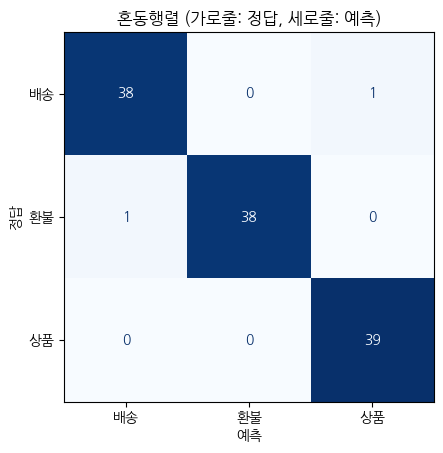

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay       # 혼동행렬 그림 도구

# 정답(y_test)과 예측(pred)으로 혼동행렬 그리기 (cmap="Blues" : 숫자가 클수록 진한 파랑)
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=LABELS, cmap="Blues", colorbar=False)
plt.title("혼동행렬 (가로줄: 정답, 세로줄: 예측)")
plt.xlabel("예측")
plt.ylabel("정답")
plt.show()

✅ **결과 확인:** 대각선이 아닌 칸에 숫자가 있으면 그만큼 헷갈린 것입니다. 예를 들어 `환불` 줄 `배송` 칸의 숫자는 **환불 문의를 배송으로 잘못 고른** 개수입니다.

### 4-3. 모델이 중요하게 본 단어
로지스틱 회귀는 유형마다 **단어별 점수(계수)**를 배웁니다. 점수가 클수록 '이 단어가 있으면 그 유형'이라고 판단합니다.

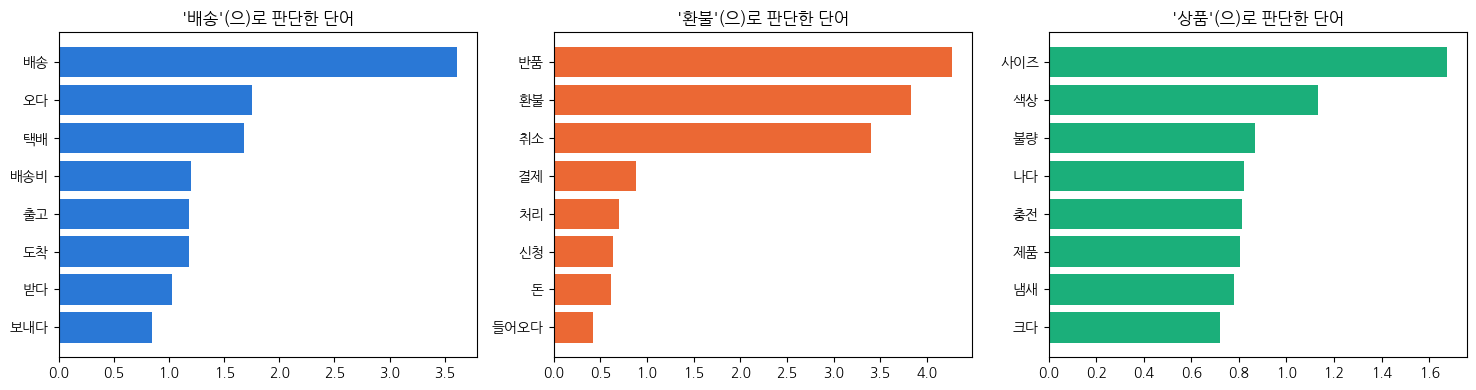

In [17]:
# 단어장 (열 순서대로 단어 이름)
words = tfidf.get_feature_names_out()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, label, color in zip(axes, LABELS, COLORS):
    # model.classes_ : 모델이 기억한 유형 순서,  .tolist().index(label) : 그중 label의 위치
    i = model.classes_.tolist().index(label)
    # model.coef_[i] : 그 유형의 단어별 점수 → 단어 이름을 붙여 큰 점수 8개
    top = pd.Series(model.coef_[i], index=words).nlargest(8)
    ax.barh(top.index[::-1], top.values[::-1], color=color)   # [::-1] : 큰 점수가 위로
    ax.set_title(f"'{label}'(으)로 판단한 단어")

plt.tight_layout()
plt.show()

✅ **결과 확인:** 3-1에서 사람이 본 **자주 나오는 단어**와 모델이 중요하게 본 단어가 비슷한가요? 다른 단어가 있다면, 그 단어는 **다른 유형에는 잘 안 나와서** 점수가 높아진 것입니다.

### 4-4. 틀린 문장 보기
모델이 틀린 문장을 직접 읽어 보면 **왜 틀렸는지** 알 수 있습니다. 이 데이터에는 `배송 온 상품이 불량이라 환불하고 싶어요`처럼 **여러 유형의 단어가 섞인 애매한 문장 10개**를 일부러 넣어 두었고, 실제 상담 문장에도 앞뒤 대화를 모르면 헷갈리는 문장이 있습니다. (이런 문장의 정답은 고객이 **최종적으로 요청한 것**을 기준으로 정했습니다.)

In [18]:
# 평가용 문장 중 정답과 예측이 다른 것만 고르기
#   df.loc[X_test.index, ...] : 평가용 문장의 원래 문의와 출처를 원본 표에서 꺼냄
wrong = pd.DataFrame({"문의": df.loc[X_test.index, "문의"], "출처": df.loc[X_test.index, "출처"],
                      "정답": y_test, "예측": pred})
wrong = wrong[wrong["정답"] != wrong["예측"]]

print("평가 문장", len(X_test), "개 중 틀린 문장:", len(wrong), "개")
wrong

평가 문장 117 개 중 틀린 문장: 2 개


,문의,출처,정답,예측
272,물류센터에 계속 머물러 있어요,직접 작성,배송,상품
354,아 그럼 말씀하신 대로 엄마가 받은 거는 반품해서 회사로 보내고 다시 남성용 받으면...,실제 상담,환불,배송


✅ **결과 확인:** 틀린 문장에 **다른 유형의 단어**가 섞여 있나요? 예를 들어 `…반품해서 회사로 보내고 다시 남성용 받으면…`은 환불 문의지만, 배송 문의에 자주 나오는 `받다`·`보내다`가 함께 들어 있습니다. 사람도 헷갈릴 만한 문장인지 생각해 보세요.





### 4-5. 내 문장 넣어 보기
새 문장도 **학습할 때와 똑같은 순서**(정리 → 단어 뽑기 → TF-IDF)로 바꾼 뒤 예측합니다.

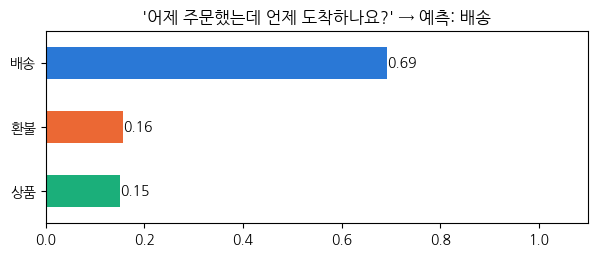

In [20]:
# ✏️ 직접 문장을 바꿔 보세요
my_text = "어제 주문했는데 언제 도착하나요?"

# 학습할 때와 똑같이 처리: clean → to_words → tfidf.transform
my_vec = tfidf.transform([to_words(clean(my_text))])

# predict_proba : 유형마다 확률,  [0] : 문장이 하나뿐이므로 첫 번째 줄
proba = pd.Series(model.predict_proba(my_vec)[0], index=model.classes_).reindex(LABELS)

# 확률 가로 막대그래프
ax = proba.plot.barh(color=COLORS, figsize=(7, 2.5))
ax.bar_label(ax.containers[0], fmt="%.2f")               # 막대 끝에 확률 (소수 둘째 자리)
ax.set_xlim(0, 1.1)                                      # 가로축 범위 0 ~ 1.1
ax.invert_yaxis()                                        # 배송이 맨 위에 오게
ax.set_title(f"'{my_text}' → 예측: {proba.idxmax()}")    # idxmax() : 확률이 가장 큰 유형
plt.show()

✅ **결과 확인:** 확률이 가장 큰 유형이 예측 결과입니다. `사이즈가 안 맞아서 반품하고 싶어요`처럼 **두 유형이 섞인 문장**을 넣으면 확률이 어떻게 나뉘는지 비교해 보세요.

---
## 정리
### ✅ 한 줄 정리
**문의 문장을 정리하고(빈 칸·중복·특수문자 제거) 형태소 분석으로 핵심 단어만 남긴 뒤, TF-IDF로 숫자 표를 만들어 로지스틱 회귀로 배송·환불·상품을 분류하고, 정확도·F1·혼동행렬로 평가했다.**

### 🗂️ 만든 파일
| 파일 | 내용 |
|---|---|
| `inquiry_clean.csv` | 정제 데이터셋 (원래 문의, 정리된 문장, 단어, 유형) |

### 🤔 생각해 볼 점 (한계)
| 한계 | 설명 |
|---|---|
| **실제 문장도 골라 온 것** | 실제 상담 문장 중 유형 단어(배송, 환불, 사이즈 등)가 들어 있고 뜻이 분명한 문장만 골랐기 때문에, 상담 전체보다 쉬운 문장이 모였습니다. |
| **평가 문장이 적음** | 평가용이 117줄뿐이라, 몇 문장만 더 맞혀도 점수가 크게 바뀝니다. `random_state`를 바꾸면 점수도 달라집니다. |
| **정답은 사람이 정함** | 애매한 문장의 정답(예: 불량 + 환불 요청 → 환불)은 하나의 기준일 뿐, 다르게 볼 수도 있습니다. |
| **단어장에 없는 단어** | 학습할 때 못 본 단어는 숫자 표에서 무시됩니다. |



**참고:** [Kiwi (kiwipiepy)](https://github.com/bab2min/kiwipiepy) · [scikit-learn TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) · [scikit-learn LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)